<a href="https://colab.research.google.com/github/Yashwini-13/DL_MINI_PROJECT/blob/main/STUDENT_PERFORMANCE_PREDICTOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 1000

# Hidden "ability" factor so features are realistically correlated
ability = rng.normal(0, 1, n)

attendance = np.clip(75 + 6*ability + rng.normal(0, 12, n), 30, 100)
previous_gpa = np.clip(6.5 + 1.2*ability + rng.normal(0, 0.8, n), 0, 10)
study_hours = np.clip(12 + 3*ability + rng.normal(0, 5, n), 0, 40)
assignment = np.clip(65 + 10*ability + 0.1*(attendance - 75) + rng.normal(0, 8, n), 0, 100)
internal = np.clip(60 + 12*ability + rng.normal(0, 9, n), 0, 100)

# Risk score: lower values on every feature increase failure probability
z = (-0.05*(attendance - 75)
     -0.04*(assignment - 65)
     -0.05*(internal - 60)
     -0.08*(study_hours - 12)
     -0.60*(previous_gpa - 6.5)
     -1.2                               # shifts overall at-risk share
     + rng.normal(0, 0.8, n))           # noise: real life isn't deterministic
prob_fail = 1 / (1 + np.exp(-z))
at_risk = (rng.random(n) < prob_fail).astype(int)

df = pd.DataFrame({
    "Attendance": attendance.round(1),
    "Assignment_Marks": assignment.round(1),
    "Internal_Score": internal.round(1),
    "Study_Hours": study_hours.round(1),
    "Previous_GPA": previous_gpa.round(2),
    "At_Risk": at_risk
})

df.to_csv("student_data.csv", index=False)
print(df.shape)
print(df["At_Risk"].value_counts(normalize=True).round(3))
df.head()

(1000, 6)
At_Risk
0    0.678
1    0.322
Name: proportion, dtype: float64


,Attendance,Assignment_Marks,Internal_Score,Study_Hours,Previous_GPA,At_Risk
0,76.1,70.2,61.3,19.2,6.50,0
1,60.0,60.3,44.8,12.3,4.72,0
2,74.5,74.6,62.7,24.1,7.75,0
3,88.3,93.6,75.1,7.1,7.83,0
4,63.3,55.8,38.7,4.8,3.03,1


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)

In [ ]:
df = pd.read_csv("student_data.csv")
print(df.shape)
df.head()

(1000, 6)


,Attendance,Assignment_Marks,Internal_Score,Study_Hours,Previous_GPA,At_Risk
0,76.1,70.2,61.3,19.2,6.50,0
1,60.0,60.3,44.8,12.3,4.72,0
2,74.5,74.6,62.7,24.1,7.75,0
3,88.3,93.6,75.1,7.1,7.83,0
4,63.3,55.8,38.7,4.8,3.03,1


In [ ]:
df = df.drop_duplicates()
df = df.fillna(df.median(numeric_only=True))
print(df.isnull().sum())


Attendance          0
Assignment_Marks    0
Internal_Score      0
Study_Hours         0
Previous_GPA        0
At_Risk             0
dtype: int64


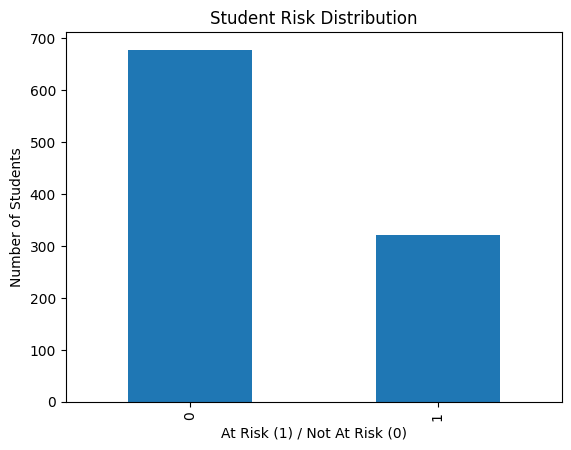

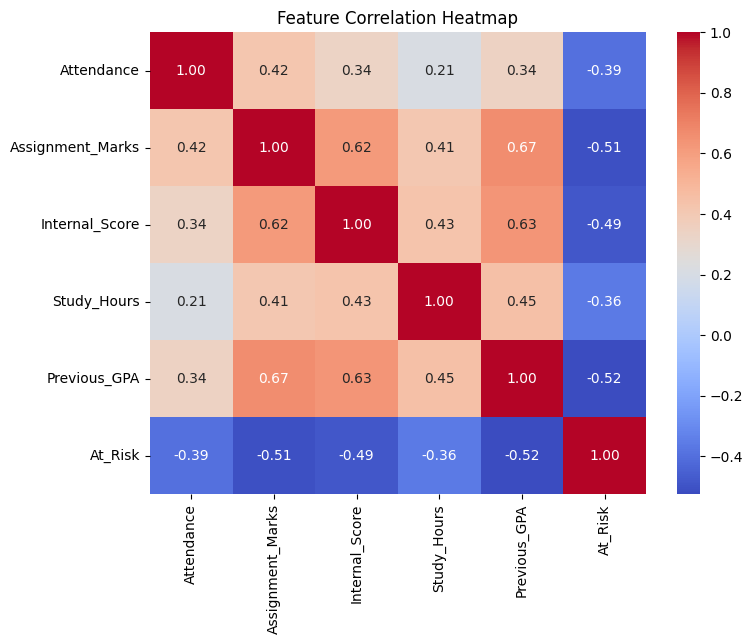

In [ ]:
# Class distribution
df["At_Risk"].value_counts().plot(kind="bar")
plt.title("Student Risk Distribution")
plt.xlabel("At Risk (1) / Not At Risk (0)")
plt.ylabel("Number of Students")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
features = ["Attendance", "Assignment_Marks", "Internal_Score",
            "Study_Hours", "Previous_GPA"]

X = df[features].values
y = df["At_Risk"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights = dict(enumerate(weights))
print(class_weights)

{0: np.float64(0.7380073800738007), 1: np.float64(1.550387596899225)}


In [ ]:
model = keras.Sequential([
    layers.Input(shape=(5,)),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7234 - loss: 0.7348 - precision: 0.6154 - recall: 0.3529 - val_accuracy: 0.7563 - val_loss: 0.6039 - val_precision: 0.6154 - val_recall: 0.7407
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7703 - loss: 0.5224 - precision: 0.6377 - recall: 0.6471 - val_accuracy: 0.7812 - val_loss: 0.5798 - val_precision: 0.6557 - val_recall: 0.7407
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8000 - loss: 0.4441 - precision: 0.6597 - recall: 0.7696 - val_accuracy: 0.7812 - val_loss: 0.5581 - val_precision: 0.6557 - val_recall: 0.7407
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7906 - loss: 0.4530 - precision: 0.6411 - recall: 0.7794 - val_accuracy: 0.8000 - val_loss: 0.5432 - val_precision: 0.6897 - val_recall: 0.7407
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7984 - loss: 0.4297 - precision: 0.6471 - recall: 0.8088 - val_accuracy: 0.8000 - val_loss: 0.5288

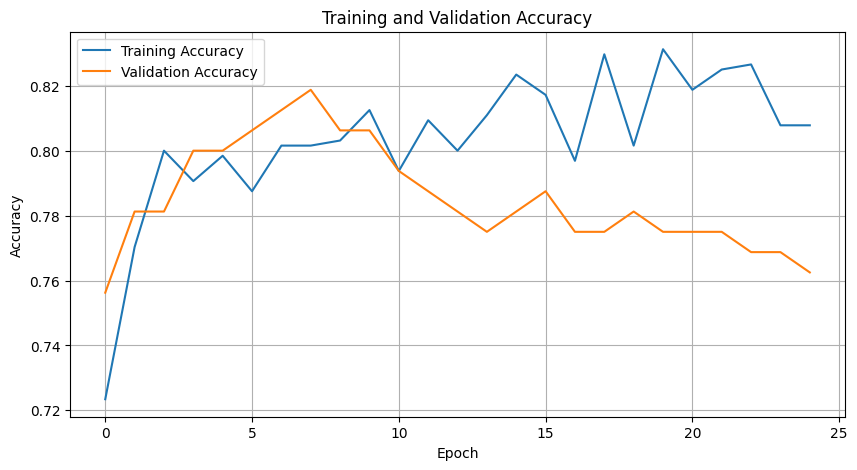

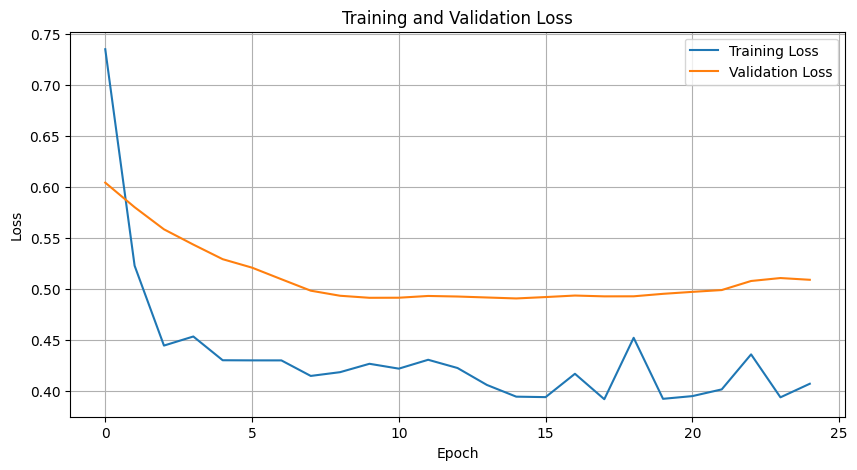

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test, y_pred,
    target_names=["Not At Risk", "At Risk"]
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
              precision    recall  f1-score   support

 Not At Risk       0.88      0.74      0.80       136
     At Risk       0.59      0.78      0.67        64

    accuracy                           0.76       200
   macro avg       0.73      0.76      0.74       200
weighted avg       0.79      0.76      0.76       200

ROC-AUC: 0.876


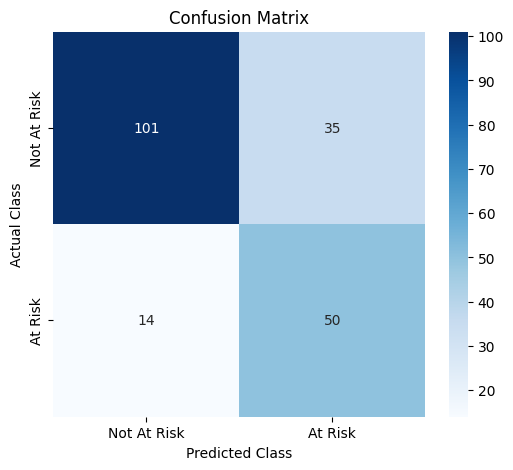

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not At Risk", "At Risk"],
            yticklabels=["Not At Risk", "At Risk"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

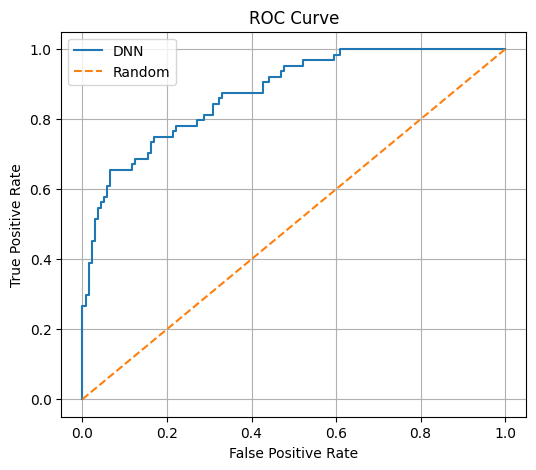

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label="DNN")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

In [ ]:
def predict_student(attendance, assignment, internal, study_hours, gpa):
    data = np.array([[attendance, assignment, internal, study_hours, gpa]])
    data = scaler.transform(data)
    prob = model.predict(data, verbose=0)[0][0]

    if prob >= 0.70:
        level = "HIGH"
        advice = "Immediate counselling and remedial classes"
    elif prob >= 0.40:
        level = "MEDIUM"
        advice = "Mentor follow-up and personalised study plan"
    else:
        level = "LOW"
        advice = "Regular monitoring"

    print("=" * 45)
    print("STUDENT RISK REPORT")
    print("=" * 45)
    print(f"Risk Probability : {prob * 100:.2f}%")
    print(f"Risk Level       : {level}")
    print(f"Recommendation   : {advice}")
    return prob

_ = predict_student(attendance=58, assignment=45, internal=40,
                    study_hours=5, gpa=5.2)

STUDENT RISK REPORT
Risk Probability : 87.96%
Risk Level       : HIGH
Recommendation   : Immediate counselling and remedial classes


In [ ]:
model.save("student_performance_model.keras")
joblib.dump(scaler, "scaler.pkl")
print("Model and scaler saved successfully!")

Model and scaler saved successfully!
